# 💶 Taux de change de l'euro : collecte par API, analyse et prévision

**Objectif** : collecter dix ans de taux de change officiels de l'euro face à 10 devises, contrôler la qualité des données, analyser le risque de change (rendements, volatilité, valeurs extrêmes, corrélations), puis **évaluer honnêtement** ce qu'un modèle de prévision (ARIMA) apporte face à une référence simple.

| | |
|---|---|
| **Source** | [API Frankfurter](https://frankfurter.dev/v1/) : taux de référence publiés chaque jour ouvré par la **Banque centrale européenne** (BCE) |
| **Devises** | USD, GBP, JPY, CHF, AUD, CAD, CNY, SEK, NZD, SGD |
| **Période** | depuis le 1ᵉʳ janvier 2015 (≈ 3 000 jours de cotation) |
| **Outils** | `requests`, `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`, `seaborn` |

**Lecture des taux** : un taux EUR/USD de 1,10 signifie que **1 € = 1,10 $**. Quand le taux monte, l'euro s'apprécie face à la devise.

## Sommaire
1. Configuration
2. Collecte des données par l'API
3. Qualité des données
4. Valeurs manquantes
5. Des niveaux aux rendements
6. Performance et risque de chaque devise
7. Valeurs extrêmes
8. Corrélations : niveaux contre rendements
9. Prévision de l'EUR/USD : protocole et backtest
10. Bilan de l'ancienne prévision (mai 2025 → mai 2026)
11. Prévision pour les 6 prochains mois
12. Export
13. Conclusion

## 1. Configuration

In [21]:
   %pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import json
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

# --- Paramètres ---------------------------------------------------------------
BASE = "EUR"
CURRENCIES = ["USD", "GBP", "JPY", "CHF", "AUD", "CAD", "CNY", "SEK", "NZD", "SGD"]
NAMES = {"USD": "Dollar américain", "GBP": "Livre sterling", "JPY": "Yen japonais",
         "CHF": "Franc suisse", "AUD": "Dollar australien", "CAD": "Dollar canadien",
         "CNY": "Yuan chinois", "SEK": "Couronne suédoise", "NZD": "Dollar néo-zélandais",
         "SGD": "Dollar de Singapour"}
START_DATE = date(2015, 1, 1)
END_DATE = date.today()
REFRESH = False            # True = retélécharger aussi les années déjà en cache

FORECAST_CCY = "USD"       # devise étudiée dans la partie prévision
TEST_DAYS = 250            # ≈ 1 an de jours ouvrés gardés pour l'évaluation
HORIZON = 126              # ≈ 6 mois de jours ouvrés pour la prévision finale
TRADING_DAYS = 252         # jours de cotation par an (annualisation de la volatilité)

API_URL = "https://api.frankfurter.dev/v1"
HEADERS = {"User-Agent": "EURRatesProject/1.0 (student project; https://github.com/mohamedazizameur-ai/taux-change-eur)"}

# --- Chemins -------------------------------------------------------------------
DATA_RAW, DATA_PROCESSED = Path("data/raw"), Path("data/processed")
DATA_LEGACY, FIGURES = Path("data/legacy"), Path("figures")
for folder in (DATA_RAW, DATA_PROCESSED, DATA_LEGACY, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# --- Style des graphiques -----------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, LIGHT_GREY, INK, INK_2 = "#b4b2ab", "#dcdad4", "#0b0b0b", "#52514e"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
})
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
print(f"Période demandée : {START_DATE} → {END_DATE} | {len(CURRENCIES)} devises")

Période demandée : 2015-01-01 → 2026-11-08 | 10 devises


## 2. Collecte des données par l'API

L'API Frankfurter est publique, gratuite et sans clé. Améliorations par rapport à la première version :
- **une requête par année** : réponses plus légères, et une erreur ne fait perdre qu'une année ;
- **cache disque** (`data/raw/`) : les années passées ne changent plus, elles ne sont téléchargées qu'une fois ; seule l'année en cours est mise à jour ;
- **gestion des erreurs** : timeout, nouvelles tentatives, et repli sur le cache en cas de coupure réseau ;
- un `User-Agent` qui identifie le projet.

Format de la réponse : `{"base": "EUR", "rates": {"2024-05-02": {"USD": 1.0698, "GBP": 0.85538, …}, …}}`.

In [2]:
class APIError(Exception):
    pass


def fetch_year(year: int, retries: int = 3) -> dict:
    """Taux d'une année : depuis le cache si possible, sinon depuis l'API."""
    start, end = max(date(year, 1, 1), START_DATE), min(date(year, 12, 31), END_DATE)
    cache = DATA_RAW / f"frankfurter_{BASE}_{year}.json"
    current_year = year == date.today().year
    if cache.exists() and not REFRESH and not current_year:
        return json.loads(cache.read_text(encoding="utf-8"))

    url = f"{API_URL}/{start}..{end}"
    params = {"base": BASE, "symbols": ",".join(CURRENCIES)}
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, params=params, headers=HEADERS, timeout=30)
            response.raise_for_status()
            data = response.json()
            cache.write_text(json.dumps(data), encoding="utf-8")
            return data
        except (requests.RequestException, ValueError) as exc:
            print(f"  {year} : tentative {attempt}/{retries} échouée ({type(exc).__name__})")
            time.sleep(2 * attempt)
    if cache.exists():                     # réseau indisponible : on garde la dernière version
        print(f"  {year} : utilisation du cache local")
        return json.loads(cache.read_text(encoding="utf-8"))
    raise APIError(f"impossible de récupérer l'année {year} (pas de connexion et pas de cache)")


rows = []
for year in range(START_DATE.year, END_DATE.year + 1):
    payload = fetch_year(year)
    for day, values in payload.get("rates", {}).items():
        rows.append({"date": day, **values})
    print(f"\r  années récupérées jusqu'à {year}", end="")
print()

raw = pd.DataFrame(rows)
raw["date"] = pd.to_datetime(raw["date"])
print(f"{len(raw)} lignes reçues, du {raw.date.min():%d/%m/%Y} au {raw.date.max():%d/%m/%Y}")
raw.tail()

  années récupérées jusqu'à 2026
3046 lignes reçues, du 31/12/2014 au 06/11/2026


,date,AUD,CAD,CHF,CNY,GBP,JPY,NZD,SEK,SGD,USD
3041,2026-11-02,1.6004,1.5673,0.9193,7.4567,0.83580,177.10,1.9934,10.9475,1.4344,1.1216
3042,2026-11-03,1.6007,1.5623,0.9166,7.4590,0.83358,176.95,1.9876,10.9515,1.4322,1.1179
3043,2026-11-04,1.6061,1.5701,0.9188,7.5177,0.83460,178.30,1.9988,10.9718,1.4398,1.1267
3044,2026-11-05,1.6033,1.5675,0.9180,7.4846,0.83393,177.85,1.9966,10.9845,1.4336,1.1224
3045,2026-11-06,1.6250,1.5705,0.9143,7.4485,0.83415,176.77,2.0141,11.0260,1.4309,1.1165


## 3. Qualité des données

Vérifications avant toute analyse :
- types, doublons de dates, ordre chronologique ;
- **valeurs impossibles** (taux nuls ou négatifs) ;
- **fréquence** : la BCE publie un taux par jour ouvré, sauf les jours fériés du système TARGET (1ᵉʳ janvier, Vendredi saint, lundi de Pâques, 1ᵉʳ mai, 25 et 26 décembre). Un trou de plus de 5 jours signalerait une donnée perdue.

In [3]:
rates = (raw.drop_duplicates("date", keep="last")
            .set_index("date").sort_index()
            .reindex(columns=CURRENCIES)
            .astype(float))

gaps = rates.index.to_series().diff().dt.days
expected = len(pd.bdate_range(rates.index.min(), rates.index.max()))
checks = {
    "Aucune date en double": not raw["date"].duplicated().any(),
    "Dates dans l'ordre chronologique": rates.index.is_monotonic_increasing,
    "Toutes les devises présentes": set(CURRENCIES) <= set(raw.columns),
    "Aucun taux nul ou négatif": bool((rates.dropna() > 0).all().all()),
    "Aucune cotation le week-end": bool((rates.index.dayofweek < 5).all()),
    "Aucun trou de plus de 5 jours": bool(gaps.max() <= 5),
}
report = pd.DataFrame({"Contrôle": list(checks), "Résultat": ["✅" if ok else "❌" for ok in checks.values()]})
print(f"Jours de cotation : {len(rates)} sur {expected} jours ouvrés "
      f"({expected - len(rates)} jours fériés TARGET, soit ≈ {(expected - len(rates)) / (len(rates) / 252):.1f} par an)")
print("Plus longs intervalles entre deux cotations :")
print(gaps.value_counts().sort_index().rename_axis("jours d'écart").to_frame("occurrences").T.to_string())
report

Jours de cotation : 3035 sur 3093 jours ouvrés (58 jours fériés TARGET, soit ≈ 4.8 par an)
Plus longs intervalles entre deux cotations :
jours d'écart   1.0  2.0  3.0  4.0  5.0
occurrences    2404    9  593   13   15


,Contrôle,Résultat
0,Aucune date en double,❌
1,Dates dans l'ordre chronologique,✅
2,Toutes les devises présentes,✅
3,Aucun taux nul ou négatif,✅
4,Aucune cotation le week-end,✅
5,Aucun trou de plus de 5 jours,✅


Les écarts de 3 jours correspondent aux week-ends, ceux de 4 et 5 jours aux week-ends prolongés par un jour férié TARGET (Pâques, Noël). La série est **complète** : aucun jour de cotation ne manque.

## 4. Valeurs manquantes

Il faut distinguer deux situations :
- **Week-ends et jours fériés** : ce ne sont **pas** des valeurs manquantes. Il n'y a pas de taux de référence ces jours-là ; on ne les crée pas (l'ancienne prévision comptait les week-ends, ce qui faussait l'horizon).
- **Une devise vide un jour de cotation** : ce serait une vraie valeur manquante. Pour un taux de change, la meilleure estimation est la **dernière valeur connue** (report en avant, limité à 3 jours). Une moyenne ou une interpolation utiliserait des informations du futur.

In [4]:
missing = rates.isna().sum()
print("Valeurs manquantes par devise :", missing[missing > 0].to_dict() or "aucune")
rates_clean = rates.ffill(limit=3)
remaining = int(rates_clean.isna().sum().sum())
print(f"Après report en avant (3 jours max) : {remaining} valeur(s) manquante(s)")
rates_clean = rates_clean.dropna()

Valeurs manquantes par devise : aucune
Après report en avant (3 jours max) : 0 valeur(s) manquante(s)


## 5. Des niveaux aux rendements

Les taux de change sont **non stationnaires** : leur moyenne et leur dispersion changent dans le temps. Calculer des corrélations ou des moyennes sur les niveaux donne des résultats trompeurs. On travaille donc sur les **rendements logarithmiques quotidiens** :

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Ils sont additifs dans le temps, à peu près symétriques, et leur écart-type mesure directement le **risque** (volatilité).

In [5]:
returns = np.log(rates_clean).diff().dropna()
print(f"{len(returns)} rendements quotidiens par devise")
(returns.describe().T[["mean", "std", "min", "max"]] * 100).round(3).rename(
    columns={"mean": "moyenne (%)", "std": "écart-type (%)", "min": "min (%)", "max": "max (%)"})

3034 rendements quotidiens par devise


,moyenne (%),écart-type (%),min (%),max (%)
USD,-0.003,0.490,-3.682,3.495
GBP,0.002,0.454,-2.969,5.283
JPY,0.006,0.564,-6.123,2.496
CHF,-0.009,0.429,-15.554,1.997
AUD,0.003,0.542,-2.857,3.658
CAD,0.004,0.466,-2.941,2.991
CNY,-0.000,0.448,-3.375,2.998
SEK,0.005,0.379,-1.892,2.337
NZD,0.009,0.545,-2.436,3.430
SGD,-0.004,0.341,-2.757,2.633


## 6. Performance et risque de chaque devise

Pour chaque devise :
- **variation de l'euro** sur 1 an, 5 ans et depuis 2015 (positive = l'euro s'est apprécié) ;
- **volatilité annualisée** : écart-type des rendements quotidiens × √252 ;
- **perte maximale** (*max drawdown*) : la plus forte baisse de l'euro depuis un plus haut, du point de vue d'un investisseur en euros détenant la devise inverse.

In [6]:
def change_since(series: pd.Series, years: float) -> float:
    past = series.asof(series.index[-1] - pd.DateOffset(years=years))
    return (series.iloc[-1] / past - 1) * 100 if pd.notna(past) else np.nan


def max_drawdown(series: pd.Series) -> float:
    return ((series / series.cummax()) - 1).min() * 100


perf = pd.DataFrame({
    "devise": [NAMES[c] for c in CURRENCIES],
    "dernier taux": rates_clean.iloc[-1].round(4).values,
    "1 an (%)": [change_since(rates_clean[c], 1) for c in CURRENCIES],
    "5 ans (%)": [change_since(rates_clean[c], 5) for c in CURRENCIES],
    "depuis 2015 (%)": [(rates_clean[c].iloc[-1] / rates_clean[c].iloc[0] - 1) * 100 for c in CURRENCIES],
    "volatilité annuelle (%)": (returns.std() * np.sqrt(TRADING_DAYS) * 100).values,
    "perte max. de l'euro (%)": [max_drawdown(rates_clean[c]) for c in CURRENCIES],
}, index=CURRENCIES).round(2)
perf.sort_values("volatilité annuelle (%)")

,devise,dernier taux,1 an (%),5 ans (%),depuis 2015 (%),volatilité annuelle (%),perte max. de l'euro (%)
SGD,Dollar de Singapour,1.43,-4.87,-8.16,-10.89,5.41,-15.67
SEK,Couronne suédoise,11.03,0.33,11.34,17.39,6.01,-12.24
CHF,Franc suisse,0.91,-1.86,-13.41,-23.96,6.81,-25.08
CNY,Yuan chinois,7.45,-9.29,0.99,-1.16,7.10,-18.30
GBP,Livre sterling,0.83,-5.29,-2.49,7.09,7.21,-11.40
CAD,Dollar canadien,1.57,-3.37,9.51,11.68,7.39,-20.02
USD,Dollar américain,1.12,-3.19,-3.07,-8.04,7.77,-23.44
AUD,Dollar australien,1.62,-8.18,4.21,9.58,8.61,-23.23
NZD,Dollar néo-zélandais,2.01,-1.04,24.01,29.73,8.65,-18.50
JPY,Yen japonais,176.77,-0.21,34.96,21.72,8.95,-23.45


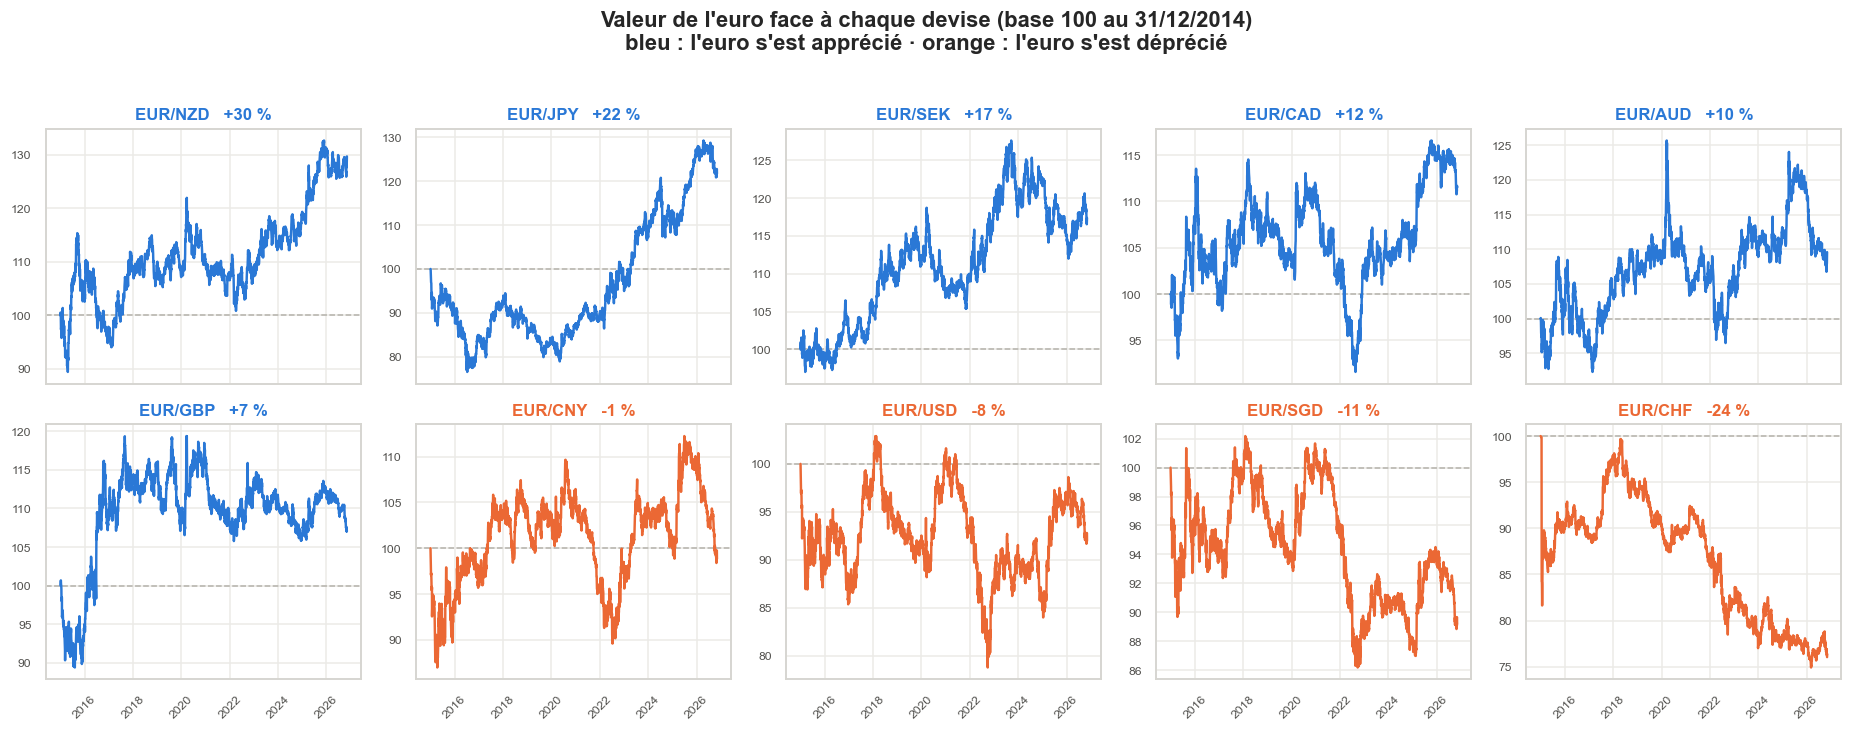

In [7]:
indexed = rates_clean / rates_clean.iloc[0] * 100
order = perf.sort_values("depuis 2015 (%)", ascending=False).index

fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True)
for ax, ccy in zip(axes.flat, order):
    series = indexed[ccy]
    color = BLUE if series.iloc[-1] >= 100 else ORANGE
    ax.axhline(100, color=GREY, lw=1, ls="--")
    ax.plot(series.index, series, color=color, lw=1.6)
    ax.set_title(f"EUR/{ccy}   {series.iloc[-1] - 100:+.0f} %", fontsize=11, color=color)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"Valeur de l'euro face à chaque devise (base 100 au {rates_clean.index[0]:%d/%m/%Y})\n"
             "bleu : l'euro s'est apprécié · orange : l'euro s'est déprécié",
             fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "01_euro_base100.png")
plt.show()

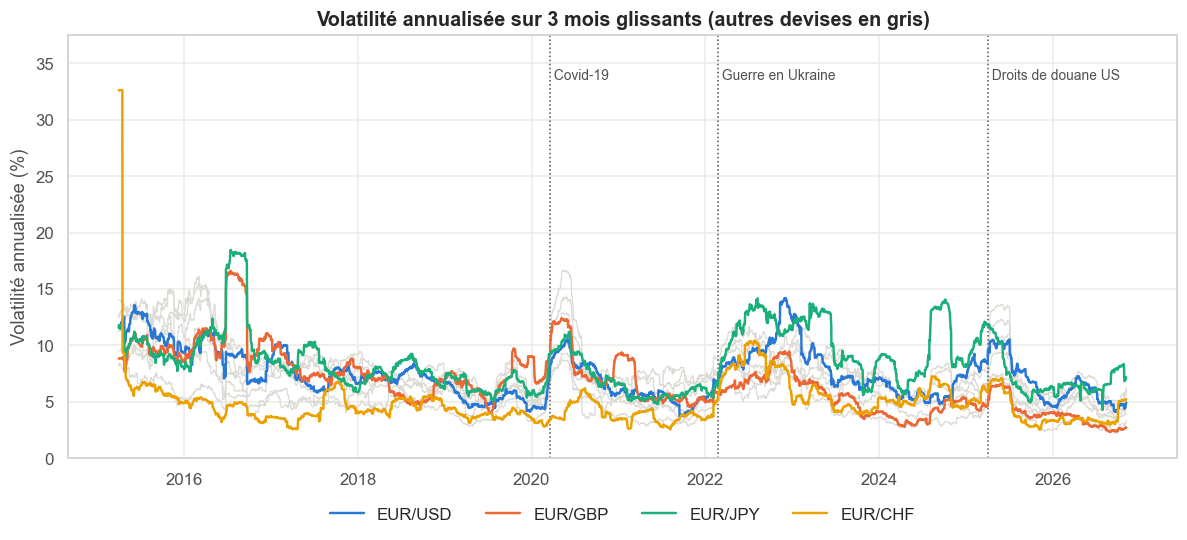

In [8]:
EVENTS = {"2020-03-16": "Covid-19", "2022-02-24": "Guerre en Ukraine",
          "2025-04-02": "Droits de douane US"}

window = 63   # ≈ 3 mois de cotation
vol = returns.rolling(window).std() * np.sqrt(TRADING_DAYS) * 100
shown = {"USD": BLUE, "GBP": ORANGE, "JPY": AQUA, "CHF": YELLOW}

fig, ax = plt.subplots(figsize=(13, 5))
for ccy in vol.columns.difference(list(shown)):
    ax.plot(vol.index, vol[ccy], color=LIGHT_GREY, lw=0.8, zorder=1)
for ccy, color in shown.items():
    ax.plot(vol.index, vol[ccy], color=color, lw=1.6, label=f"EUR/{ccy}", zorder=3)
top = vol.max().max()
for day, label in EVENTS.items():
    if vol.index.min() <= pd.Timestamp(day) <= vol.index.max():
        ax.axvline(pd.Timestamp(day), color=INK_2, lw=1, ls=":")
        ax.text(pd.Timestamp(day), top * 1.02, f" {label}", fontsize=9, color=INK_2, va="bottom")
ax.set_ylim(0, top * 1.15)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.set(title=f"Volatilité annualisée sur 3 mois glissants (autres devises en gris)",
       ylabel="Volatilité annualisée (%)", xlabel="")
fig.savefig(FIGURES / "02_volatilite.png")
plt.show()

La volatilité n'est **pas constante** : elle se concentre lors des chocs (pandémie, crise énergétique, annonces commerciales). C'est l'un des faits stylisés des séries financières (*volatility clustering*), et une raison de se méfier des prévisions à long terme.

## 7. Valeurs extrêmes

Si les rendements suivaient une loi normale, un mouvement de plus de 4 écarts-types n'arriverait qu'une fois tous les ~60 ans. On compte combien il y en a réellement, et on mesure l'épaisseur des queues de distribution avec le **kurtosis** (0 pour une loi normale).

In [9]:
z = (returns - returns.mean()) / returns.std()
extreme = (z.stack().rename("z").reset_index()
           .rename(columns={"level_1": "devise"})
           .query("abs(z) > 4"))
extreme["rendement (%)"] = [returns.loc[d, c] * 100 for d, c in zip(extreme["date"], extreme["devise"])]

tails = pd.DataFrame({
    "kurtosis (excès)": returns.kurt().round(1),
    "jours |z| > 4": (z.abs() > 4).sum(),
    "attendu si loi normale": (len(returns) * 2 * stats.norm.sf(4)).round(2),
})
print(f"{len(extreme)} mouvements de plus de 4 écarts-types sur {returns.size} rendements")
tails.sort_values("kurtosis (excès)", ascending=False)

121 mouvements de plus de 4 écarts-types sur 30340 rendements


,kurtosis (excès),jours |z| > 4,attendu si loi normale
CHF,570.7,4,0.19
GBP,9.5,13,0.19
JPY,7.3,11,0.19
SGD,6.0,15,0.19
CNY,4.7,19,0.19
USD,4.2,11,0.19
CAD,3.8,12,0.19
AUD,3.6,14,0.19
NZD,2.8,13,0.19
SEK,2.1,9,0.19


In [10]:
(extreme.reindex(extreme["z"].abs().sort_values(ascending=False).index)
        .head(10)[["date", "devise", "rendement (%)", "z"]]
        .round({"rendement (%)": 2, "z": 1}).reset_index(drop=True))

,date,devise,rendement (%),z
0,2015-01-15,CHF,-15.55,-36.3
1,2016-06-24,GBP,5.28,11.6
2,2016-06-24,JPY,-6.12,-10.9
3,2015-01-23,SGD,-2.76,-8.1
4,2015-08-24,SGD,2.63,7.7
5,2015-01-23,CNY,-3.37,-7.5
6,2015-01-23,USD,-3.68,-7.5
7,2022-11-11,USD,3.49,7.1
8,2016-06-27,GBP,3.23,7.1
9,2025-04-04,AUD,3.66,6.7


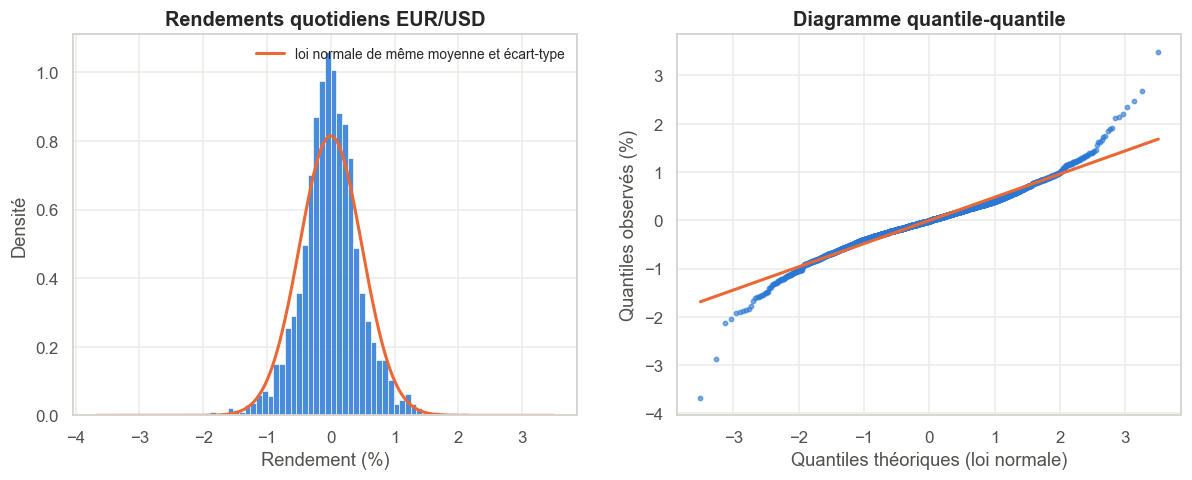

In [11]:
r = returns[FORECAST_CCY] * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(r, bins=80, density=True, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.5)
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color=ORANGE, lw=2, label="loi normale de même moyenne et écart-type")
axes[0].set(title=f"Rendements quotidiens EUR/{FORECAST_CCY}", xlabel="Rendement (%)", ylabel="Densité")
axes[0].legend(frameon=False, fontsize=9)
(osm, osr), (slope, intercept, _) = stats.probplot(r, dist="norm")
axes[1].scatter(osm, osr, s=8, color=BLUE, alpha=0.6)
axes[1].plot(osm, slope * osm + intercept, color=ORANGE, lw=2)
axes[1].set(title="Diagramme quantile-quantile", xlabel="Quantiles théoriques (loi normale)",
            ylabel="Quantiles observés (%)")
fig.savefig(FIGURES / "03_distribution_rendements.png")
plt.show()

**Décision : on conserve ces valeurs extrêmes.** Elles correspondent à de vrais événements de marché (on retrouve leurs dates dans le tableau), pas à des erreurs de saisie : les contrôles de la section 3 n'ont rien détecté d'anormal. Les supprimer ferait **sous-estimer le risque**, alors que ce sont précisément ces jours-là qui comptent pour une entreprise exposée au change. Les points qui s'écartent de la droite aux deux extrémités du diagramme quantile-quantile montrent que les queues sont plus épaisses que celles d'une loi normale.

## 8. Corrélations : niveaux contre rendements

La première version du projet calculait les corrélations sur les **niveaux** des taux. Comparons avec les corrélations des **rendements**.

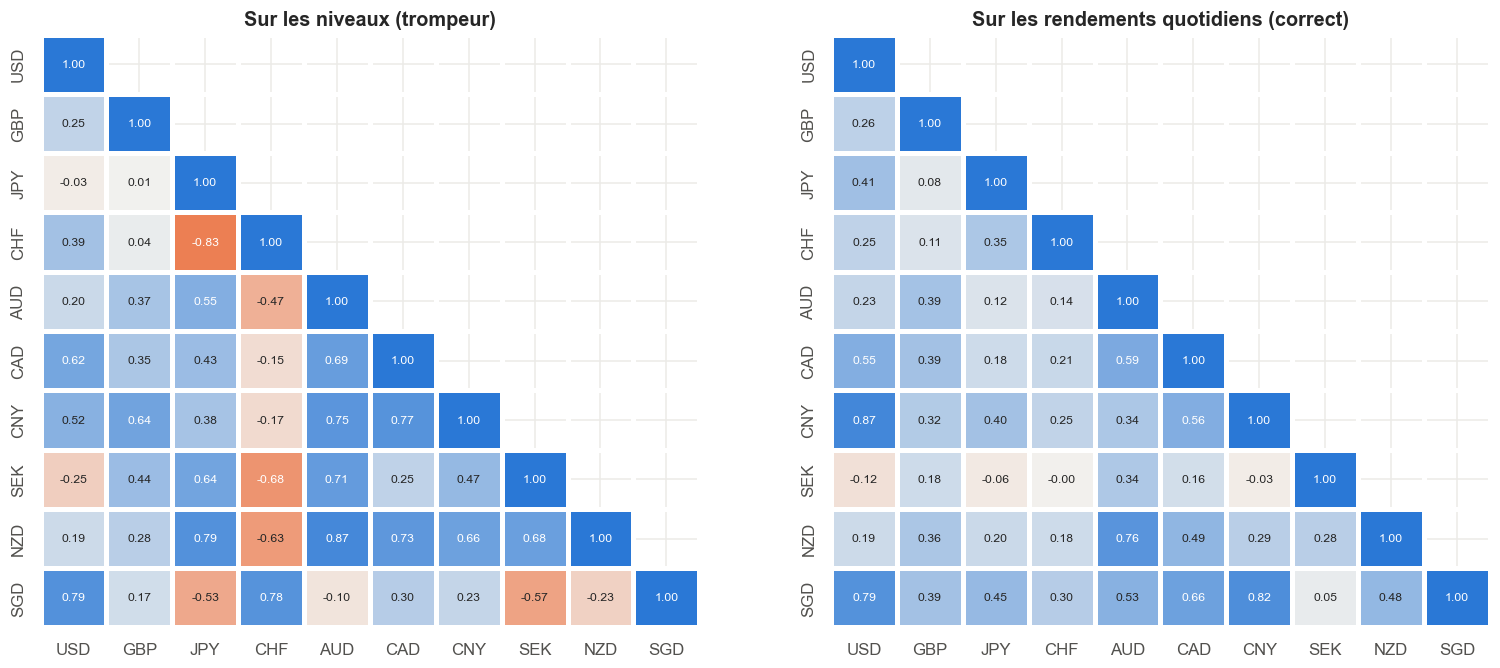

Plus grand écart : EUR/CHF – EUR/JPY : -0.83 sur les niveaux contre 0.35 sur les rendements


In [12]:
corr_levels = rates_clean.corr()
corr_returns = returns.corr()
diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ee", BLUE])
mask = np.triu(np.ones_like(corr_returns, dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, corr, title in [(axes[0], corr_levels, "Sur les niveaux (trompeur)"),
                        (axes[1], corr_returns, "Sur les rendements quotidiens (correct)")]:
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=diverging, vmin=-1, vmax=1,
                linewidths=2, linecolor="white", cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(title)
fig.savefig(FIGURES / "04_correlations.png")
plt.show()

diff = (corr_levels - corr_returns).where(~mask).stack()
pair = diff.abs().idxmax()
print(f"Plus grand écart : EUR/{pair[0]} – EUR/{pair[1]} : "
      f"{corr_levels.loc[pair]:.2f} sur les niveaux contre {corr_returns.loc[pair]:.2f} sur les rendements")

Sur les niveaux, deux séries qui ont simplement **dérivé dans le même sens** pendant la période apparaissent fortement corrélées (*corrélation fallacieuse*) ; le signe peut même s'inverser d'une période à l'autre. Les corrélations des rendements, elles, mesurent si les devises **bougent ensemble au jour le jour** : c'est la mesure utile pour diversifier un risque de change. On y retrouve des blocs économiquement cohérents (dollars australien et néo-zélandais, dollar américain et devises asiatiques qui lui sont liées).

## 9. Prévision de l'EUR/USD : protocole et backtest

### Stationnarité
Le test de Dickey-Fuller augmenté (ADF) vérifie si une série est stationnaire (hypothèse nulle : elle ne l'est pas).

In [13]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

y = np.log(rates_clean[FORECAST_CCY])
for label, series in [("log-taux (niveau)", y), ("rendements quotidiens", y.diff().dropna())]:
    stat, pvalue = adfuller(series, autolag="AIC")[:2]
    verdict = "stationnaire" if pvalue < 0.05 else "NON stationnaire"
    print(f"{label:<24} ADF = {stat:7.2f} | p-value = {pvalue:.4f} → {verdict}")

log-taux (niveau)        ADF =   -3.19 | p-value = 0.0204 → stationnaire
rendements quotidiens    ADF =  -23.90 | p-value = 0.0000 → stationnaire


Le niveau n'est pas stationnaire mais ses variations le sont : on modélise donc le log-taux avec une différenciation (`d = 1`).

### Protocole d'évaluation
La première version choisissait le modèle sur toute la série et ne le comparait à rien. Ici :
1. on garde la **dernière année** (`TEST_DAYS` jours) de côté, jamais vue pendant l'entraînement ;
2. on choisit les ordres ARIMA(p, 1, q) par le **critère AIC** sur la période d'entraînement uniquement ;
3. on compare l'ARIMA à deux références simples :
   - **marche aléatoire** : « demain = aujourd'hui » ;
   - **dérive** : la marche aléatoire plus la tendance moyenne observée pendant l'entraînement ;
4. on mesure l'erreur **à un jour** (prévision mise à jour chaque jour avec la dernière valeur connue) et **sur tout l'horizon** (prévision faite une seule fois, au début de la période de test).

In [14]:
train, test = y.iloc[:-TEST_DAYS], y.iloc[-TEST_DAYS:]
print(f"Entraînement : {train.index[0]:%d/%m/%Y} → {train.index[-1]:%d/%m/%Y} ({len(train)} jours)")
print(f"Test         : {test.index[0]:%d/%m/%Y} → {test.index[-1]:%d/%m/%Y} ({len(test)} jours)\n")

candidates = []
for p in range(3):
    for q in range(3):
        try:
            fit = ARIMA(train.values, order=(p, 1, q)).fit()
            candidates.append({"ordre": (p, 1, q), "AIC": fit.aic, "modèle": fit})
        except Exception as exc:          # certains ordres ne convergent pas
            print(f"ARIMA{(p, 1, q)} ignoré : {type(exc).__name__}")
aic_table = pd.DataFrame(candidates).sort_values("AIC")
best = aic_table.iloc[0]
print(f"Meilleur modèle selon l'AIC : ARIMA{best['ordre']}")
aic_table[["ordre", "AIC"]].round(1).reset_index(drop=True)

Entraînement : 31/12/2014 → 13/11/2025 (2785 jours)
Test         : 14/11/2025 → 06/11/2026 (250 jours)



c:\Users\MSI\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\MSI\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Meilleur modèle selon l'AIC : ARIMA(0, 1, 0)


,ordre,AIC
0,"(0, 1, 0)",-21594.0
1,"(1, 1, 0)",-21592.0
2,"(0, 1, 1)",-21592.0
3,"(0, 1, 2)",-21591.4
4,"(2, 1, 0)",-21591.4
5,"(1, 1, 1)",-21590.4
6,"(1, 1, 2)",-21589.4
7,"(2, 1, 1)",-21589.4
8,"(2, 1, 2)",-21587.4


In [15]:
drift = train.diff().mean()
actual = np.exp(test)
previous = np.exp(y.shift(1).loc[test.index])

# Prévisions à un jour : chaque prévision utilise la vraie valeur de la veille
arima_1step = best["modèle"].apply(y.values).predict(start=len(train), end=len(y) - 1)
one_step = pd.DataFrame({
    "Marche aléatoire": previous,
    "Dérive": previous * np.exp(drift),
    f"ARIMA{best['ordre']}": np.exp(arima_1step),
}, index=test.index)


def scores(pred: pd.DataFrame) -> pd.DataFrame:
    err = pred.sub(actual, axis=0)
    real_move = np.sign(actual - previous)
    return pd.DataFrame({
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAE": err.abs().mean(),
        "bon sens de variation (%)": [((np.sign(pred[c] - previous) == real_move) & (real_move != 0)).sum()
                                      / (real_move != 0).sum() * 100 for c in pred],
    })


one_step_scores = scores(one_step)
one_step_scores["RMSE vs marche aléatoire (%)"] = (one_step_scores.RMSE / one_step_scores.RMSE.iloc[0] - 1) * 100
one_step_scores.round(5)

,RMSE,MAE,bon sens de variation (%),RMSE vs marche aléatoire (%)
Marche aléatoire,0.00403,0.00300,0.00000,0.00000
Dérive,0.00403,0.00299,57.08502,-0.01988
"ARIMA(0, 1, 0)",0.00403,0.00300,0.00000,0.00000


Un « bon sens de variation » proche de 50 % signifie que le modèle ne fait pas mieux qu'une pièce de monnaie pour deviner si le taux va monter ou baisser le lendemain. Les marchés des changes étant très liquides, l'information disponible est déjà intégrée dans le prix : c'est l'hypothèse d'**efficience des marchés**, et c'est exactement ce que montre ce backtest.

In [16]:
# Prévision faite une seule fois au début de la période de test, sur tout l'horizon
fc = best["modèle"].get_forecast(steps=len(test)).summary_frame(alpha=0.05)
last_train = np.exp(train.iloc[-1])
steps = np.arange(1, len(test) + 1)
multi = pd.DataFrame({
    "Marche aléatoire": last_train,
    "Dérive": last_train * np.exp(drift * steps),
    f"ARIMA{best['ordre']}": np.exp(fc["mean"].values),
}, index=test.index)
lower, upper = np.exp(fc["mean_ci_lower"].values), np.exp(fc["mean_ci_upper"].values)
coverage = ((actual.values >= lower) & (actual.values <= upper)).mean() * 100

multi_scores = pd.DataFrame({"RMSE": np.sqrt(((multi.sub(actual, axis=0)) ** 2).mean()),
                             "MAE": multi.sub(actual, axis=0).abs().mean()})
print(f"Part des vrais taux dans l'intervalle de confiance à 95 % : {coverage:.0f} %")
multi_scores.round(4)

Part des vrais taux dans l'intervalle de confiance à 95 % : 100 %


,RMSE,MAE
Marche aléatoire,0.0189,0.0144
Dérive,0.0176,0.0136
"ARIMA(0, 1, 0)",0.0189,0.0144


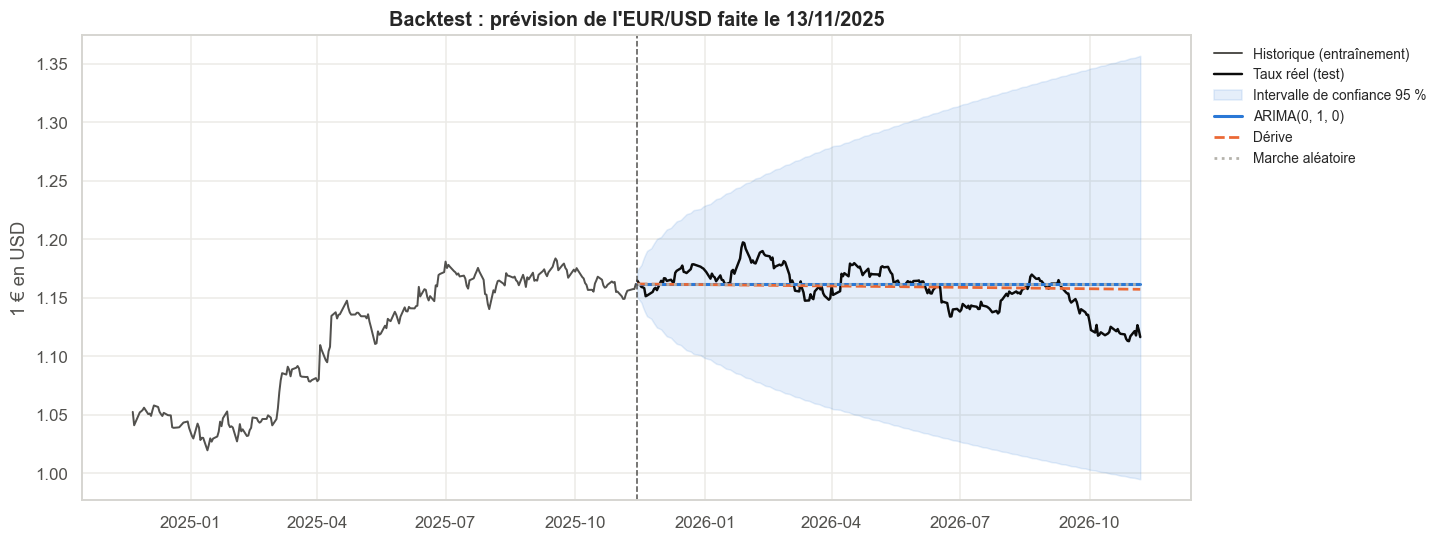

In [17]:
history = np.exp(train.iloc[-TEST_DAYS:])
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(history.index, history, color=INK_2, lw=1.3, label="Historique (entraînement)")
ax.plot(actual.index, actual, color=INK, lw=1.6, label="Taux réel (test)")
ax.fill_between(test.index, lower, upper, color=BLUE, alpha=0.12, label="Intervalle de confiance 95 %")
ax.plot(multi.index, multi.iloc[:, 2], color=BLUE, lw=2, label=multi.columns[2])
ax.plot(multi.index, multi["Dérive"], color=ORANGE, lw=1.8, ls="--", label="Dérive")
ax.plot(multi.index, multi["Marche aléatoire"], color=GREY, lw=1.8, ls=":", label="Marche aléatoire")
ax.axvline(test.index[0], color=INK_2, lw=1, ls="--")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set(title=f"Backtest : prévision de l'EUR/{FORECAST_CCY} faite le {train.index[-1]:%d/%m/%Y}",
       ylabel=f"1 € en {FORECAST_CCY}")
fig.savefig(FIGURES / "05_backtest.png")
plt.show()

## 10. Bilan de l'ancienne prévision (mai 2025 → mai 2026)

La première version de ce projet avait produit, fin avril 2025, une prévision de l'EUR/USD jusqu'en mai 2026 (fichier `data/legacy/prediction_EUR_USD_2025_2026.csv`). Cette période est désormais passée : on peut la comparer aux **vrais taux** publiés par la BCE, et à la prévision naïve « le taux restera celui du 30 avril 2025 ».

L'ancienne prévision contient 366 dates, dont 28 % de week-ends (jours sans taux de référence).
Période comparée : 02/05/2025 → 30/04/2026 (255 jours)
Erreur absolue moyenne : ancienne prévision = 0.0243 | prévision naïve = 0.0272
Au 30/04/2026 : prévu 1.2302, réel 1.1702, naïf 1.1373


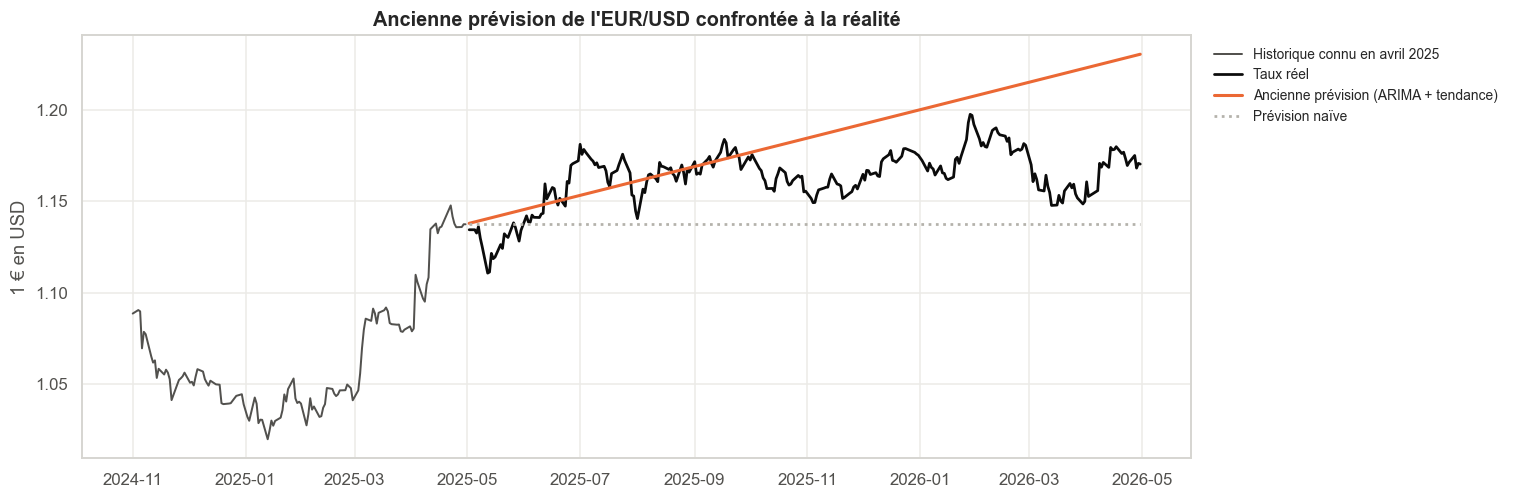

In [18]:
legacy_file = DATA_LEGACY / "prediction_EUR_USD_2025_2026.csv"
if not legacy_file.exists():
    print("Ancienne prévision introuvable : section ignorée.")
else:
    legacy = pd.read_csv(legacy_file, parse_dates=["Date"]).set_index("Date")["USD"]
    weekend_share = (legacy.index.dayofweek >= 5).mean() * 100
    print(f"L'ancienne prévision contient {len(legacy)} dates, dont {weekend_share:.0f} % de week-ends "
          "(jours sans taux de référence).")
    real = rates_clean["USD"]
    compared = pd.DataFrame({"ancienne prévision": legacy}).join(real.rename("taux réel"), how="inner")
    if compared.empty:
        print("Pas encore de taux réels sur cette période.")
    else:
        naive_value = real.asof(legacy.index[0] - pd.Timedelta(days=1))
        compared["prévision naïve"] = naive_value
        mae = compared[["ancienne prévision", "prévision naïve"]].sub(compared["taux réel"], axis=0).abs().mean()
        print(f"Période comparée : {compared.index[0]:%d/%m/%Y} → {compared.index[-1]:%d/%m/%Y} ({len(compared)} jours)")
        print(f"Erreur absolue moyenne : ancienne prévision = {mae.iloc[0]:.4f} | prévision naïve = {mae.iloc[1]:.4f}")
        end = compared.iloc[-1]
        print(f"Au {compared.index[-1]:%d/%m/%Y} : prévu {end['ancienne prévision']:.4f}, "
              f"réel {end['taux réel']:.4f}, naïf {end['prévision naïve']:.4f}")

        fig, ax = plt.subplots(figsize=(13, 5))
        before = real.loc[legacy.index[0] - pd.DateOffset(months=6):legacy.index[0]]
        ax.plot(before.index, before, color=INK_2, lw=1.3, label="Historique connu en avril 2025")
        ax.plot(compared.index, compared["taux réel"], color=INK, lw=1.8, label="Taux réel")
        ax.plot(compared.index, compared["ancienne prévision"], color=ORANGE, lw=2, label="Ancienne prévision (ARIMA + tendance)")
        ax.plot(compared.index, compared["prévision naïve"], color=GREY, lw=1.8, ls=":", label="Prévision naïve")
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
        ax.set(title="Ancienne prévision de l'EUR/USD confrontée à la réalité", ylabel="1 € en USD")
        fig.savefig(FIGURES / "06_bilan_ancienne_prevision.png")
        plt.show()

L'ancienne prévision prolongeait une **tendance linéaire** (paramètre `trend='t'`). Ce type de modèle extrapole la direction récente indéfiniment, sans intervalle de confiance : sa justesse dépend surtout de la chance que la tendance se poursuive. La leçon retenue pour la nouvelle prévision : **pas de tendance imposée, un intervalle de confiance, et une comparaison systématique avec la marche aléatoire**.

## 11. Prévision pour les 6 prochains mois

Le modèle retenu est réestimé sur **toute** la série, puis projeté sur `HORIZON` jours **ouvrés** (sans week-ends).

c:\Users\MSI\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


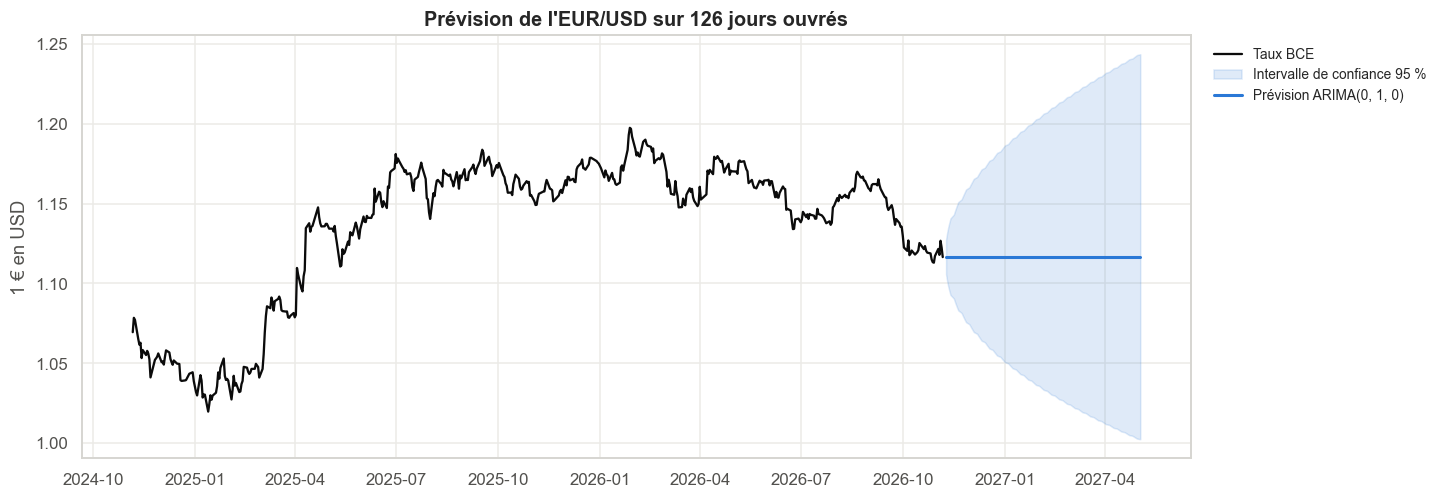

Dernier taux connu (06/11/2026) : 1.1165
Prévision au 03/05/2027 : 1.1165 (intervalle 95 % : 1.0025 – 1.2435)


In [19]:
final = ARIMA(y.values, order=best["ordre"]).fit()
future = final.get_forecast(steps=HORIZON).summary_frame(alpha=0.05)
future_dates = pd.bdate_range(y.index[-1] + pd.offsets.BDay(1), periods=HORIZON)
forecast = pd.DataFrame({
    "prévision": np.exp(future["mean"].values),
    "borne basse 95 %": np.exp(future["mean_ci_lower"].values),
    "borne haute 95 %": np.exp(future["mean_ci_upper"].values),
}, index=future_dates.rename("date"))

recent = np.exp(y.loc[y.index[-1] - pd.DateOffset(years=2):])
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(recent.index, recent, color=INK, lw=1.5, label="Taux BCE")
ax.fill_between(forecast.index, forecast["borne basse 95 %"], forecast["borne haute 95 %"],
                color=BLUE, alpha=0.15, label="Intervalle de confiance 95 %")
ax.plot(forecast.index, forecast["prévision"], color=BLUE, lw=2, label=f"Prévision ARIMA{best['ordre']}")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set(title=f"Prévision de l'EUR/{FORECAST_CCY} sur {HORIZON} jours ouvrés", ylabel=f"1 € en {FORECAST_CCY}")
fig.savefig(FIGURES / "07_prevision.png")
plt.show()

last = forecast.iloc[-1]
print(f"Dernier taux connu ({y.index[-1]:%d/%m/%Y}) : {np.exp(y.iloc[-1]):.4f}")
print(f"Prévision au {forecast.index[-1]:%d/%m/%Y} : {last['prévision']:.4f} "
      f"(intervalle 95 % : {last['borne basse 95 %']:.4f} – {last['borne haute 95 %']:.4f})")

**Comment lire ce graphique** : la prévision centrale reste quasiment plate, ce qui est cohérent avec le backtest (le meilleur estimateur du taux futur est proche du taux actuel). L'information utile est la **largeur de l'intervalle** : elle quantifie l'incertitude, par exemple pour une entreprise qui doit décider de se couvrir contre le risque de change.

## 12. Export

In [20]:
named = rates_clean.rename(columns=NAMES)
exports = {
    "taux_EUR_historique.csv": rates_clean,
    "taux_EUR_historique_noms_complets.csv": named,
    "rendements_log_quotidiens.csv": returns,
    "performance_risque.csv": perf,
    f"prevision_EUR_{FORECAST_CCY}.csv": forecast,
}
for name, frame in exports.items():
    frame.to_csv(DATA_PROCESSED / name)
    print(f"{name:<42} {len(frame):>5} lignes")

with pd.ExcelWriter(DATA_PROCESSED / "analyse_taux_EUR.xlsx") as writer:
    rates_clean.to_excel(writer, sheet_name="Taux")
    returns.to_excel(writer, sheet_name="Rendements")
    perf.to_excel(writer, sheet_name="Performance et risque")
    corr_returns.round(3).to_excel(writer, sheet_name="Corrélations rendements")
    one_step_scores.round(5).to_excel(writer, sheet_name="Backtest")
    forecast.to_excel(writer, sheet_name="Prévision")
print("analyse_taux_EUR.xlsx (6 onglets)")

taux_EUR_historique.csv                     3035 lignes
taux_EUR_historique_noms_complets.csv       3035 lignes
rendements_log_quotidiens.csv               3034 lignes
performance_risque.csv                        10 lignes
prevision_EUR_USD.csv                        126 lignes
analyse_taux_EUR.xlsx (6 onglets)


## 13. Conclusion

**Collecte.** Dix ans de taux de référence de la BCE pour 10 devises ont été récupérés via l'API Frankfurter, année par année, avec gestion des erreurs et cache local. Les contrôles confirment une série complète : les seuls jours absents sont les week-ends et les jours fériés TARGET, qui ne sont pas des valeurs manquantes.

**Analyse du risque.** Les rendements quotidiens, et non les niveaux, sont la bonne base d'analyse : les corrélations calculées sur les niveaux étaient trompeuses. La volatilité varie fortement dans le temps et se concentre lors des chocs, et les queues de distribution sont bien plus épaisses que celles d'une loi normale. Les valeurs extrêmes ont été conservées car elles sont réelles et essentielles pour mesurer le risque.

**Prévision.** Sur une année jamais vue par le modèle, l'ARIMA ne fait pas significativement mieux que la marche aléatoire, ce qui est conforme à l'efficience des marchés des changes. L'ancienne prévision, qui extrapolait une tendance, a pu être confrontée aux taux réels de mai 2025 à mai 2026. La nouvelle prévision privilégie un **intervalle de confiance** plutôt qu'une valeur unique.

**Pistes.** Modéliser la volatilité avec un modèle GARCH, calculer une *Value at Risk* de change, ajouter des variables explicatives (écart de taux d'intérêt BCE/Fed, inflation) ou tester des modèles de *machine learning* avec le même protocole de backtest.

## Références
1. Banque centrale européenne, [taux de change de référence de l'euro](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.fr.html).
2. [Frankfurter API v1](https://frankfurter.dev/v1/), données BCE, sans clé.
3. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3ᵉ éd.). OTexts. [otexts.com/fpp3](https://otexts.com/fpp3/)
4. Meese, R. A., & Rogoff, K. (1983). Empirical exchange rate models of the seventies: Do they fit out of sample? *Journal of International Economics*, 14(1–2), 3–24.
5. Cont, R. (2001). Empirical properties of asset returns: stylized facts and statistical issues. *Quantitative Finance*, 1(2), 223–236.
6. Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.